# Lab 3C — Support Vector Machines, from scratch (STUDENT)
**Mathematics & Statistics for Machine Learning — Albert School, MSc 1 (MSA-DATI07-04)**

In this lab you rebuild, step by step, everything we did in Lecture 3C on SVMs:

| Part | What you do | Lecture slides |
|---|---|---|
| 1 | Geometry: distance to a border, width of the street | Geometry 1–3 |
| 2 | The hard-margin SVM on 4 points: support vectors, width | Exercise 3C.1 |
| 3 | The hinge loss, and how it differs from the logistic loss | Hinge loss, 3 cases |
| 4 | The soft margin on the 7-point 1-D example: cost $J(w,b)$, role of $C$ | 1-D example |
| 5 | Training an SVM yourself with **sub-gradient descent** | Hinge route |
| 6 | Support vectors and the three kinds of points ($\alpha_i$) | Soft-margin dual |
| 7 | Kernels: the feature map, the kernel trick, an RBF prediction by hand | Kernels |
| 8 | A real data set: breast cancer, scaling, tuning $C$ and $\gamma$ | SVMs in practice |

**How to work.** Run the cells in order. Cells marked `# TODO` are yours. After each TODO a **checkpoint** cell prints what you should get.

Labels are always $y_i \in \{-1, +1\}$ and the score is $f(x) = w^\top x + b$.

In [2]:
# Setup (everything is pre-installed on Colab)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer, make_moons, make_circles
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
np.set_printoptions(precision=3, suppress=True)
BLUE, ORANGE, NAVY, SKY, RED = "#3333AB", "#E67E22", "#212447", "#59ADDC", "#C8323C"
print("ready")

ready


## Part 1 — Geometry of a border

For a border $w^\top x + b = 0$:

* $w$ is perpendicular to the border;
* the (signed) distance of a point $x$ to the border is $\delta = \dfrac{w^\top x + b}{\lVert w \rVert}$;
* with the canonical scaling (closest points have $y_i f(x_i) = 1$), the street has width $\dfrac{2}{\lVert w\rVert}$.

**Task 1.1.** Write `distance(w, b, x)` and `street_width(w)`.

In [3]:
def distance(w, b, x):
    return (w @ x + b) / np.linalg.norm(w)

def street_width(w):
    return 2 / np.linalg.norm(w)

In [4]:
# Checkpoint (lecture example: border 3x1 + 4x2 - 12 = 0, point (4,4))
print("distance of (4,4):", distance(np.array([3., 4.]), -12., np.array([4., 4.])), "  expected 3.2")
print("width for w=(3,4):", street_width(np.array([3., 4.])), "  expected 0.4")
print("width for w=(0.6,0.8):", street_width(np.array([0.6, 0.8])), "  expected 2.0")

distance of (4,4): 3.2   expected 3.2
width for w=(3,4): 0.4   expected 0.4
width for w=(0.6,0.8): 2.0   expected 2.0


**Task 1.2 (question).** $(w,b)=((3,4),-12)$ and $((6,8),-24)$ give the same border. What happens to the distance computed by `distance`? What happens to $f(x)$? Why do we need a convention to fix the scale?

**Answer 1.2.** The distance does not change. f(x) is multiplied by 2. The scale of (w, b) is free, so we fix it with y f = 1 on the closest points.

In [5]:
xt = np.array([4., 4.])
for w_, b_ in [(np.array([3., 4.]), -12.), (np.array([6., 8.]), -24.)]:
    print("f =", w_ @ xt + b_, " distance =", distance(w_, b_, xt))

f = 16.0  distance = 3.2
f = 32.0  distance = 3.2


## Part 2 — The hard-margin SVM on 4 points (Exercise 3C.1)

Repay ($+1$): $(2,2)$, $(3,2)$. Default ($-1$): $(1,1)$, $(0,1)$. The solution is $w=(1,1)$, $b=-3$.

**Task 2.1.** Compute $y_i f(x_i)$ for the 4 points. Which ones are support vectors ($y_if=1$)? Compute the width.

In [6]:
X4 = np.array([[2, 2], [3, 2], [1, 1], [0, 1]], float)
y4 = np.array([1, 1, -1, -1], float)
w, b = np.array([1., 1.]), -3.
margins = y4 * (X4 @ w + b)
print("y*f      :", margins)
print("support  :", X4[np.isclose(margins, 1)])
print("width    :", street_width(w))

y*f      : [1. 2. 1. 2.]
support  : [[2. 2.]
 [1. 1.]]
width    : 1.414213562373095


In [7]:
# Checkpoint: y*f = [1, 2, 1, 2], support vectors (2,2) and (1,1), width 1.414
svc = SVC(kernel="linear", C=1e6).fit(X4, y4)       # sklearn's answer, for comparison
print("sklearn w =", svc.coef_[0], " b =", svc.intercept_[0], " support vectors:\n", svc.support_vectors_)

sklearn w = [1. 1.]  b = -3.0  support vectors:
 [[1. 1.]
 [2. 2.]]


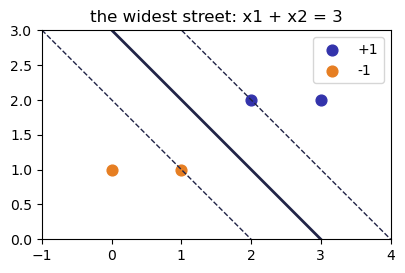

In [8]:
def plot_street(ax, X, y, w, b, title=""):
    gx = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 100)
    for off, st in [(0, "-"), (1, "--"), (-1, "--")]:
        ax.plot(gx, (off - b - w[0] * gx) / w[1], color=NAVY, ls=st, lw=2 if off == 0 else 1)
    ax.scatter(X[y > 0, 0], X[y > 0, 1], color=BLUE, s=60, label="+1")
    ax.scatter(X[y < 0, 0], X[y < 0, 1], color=ORANGE, s=60, label="-1")
    ax.set_aspect("equal"); ax.set_title(title); ax.legend()
    ax.set_xlim(X[:, 0].min() - 1, X[:, 0].max() + 1); ax.set_ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)

fig, ax = plt.subplots(figsize=(4.5, 4))
plot_street(ax, X4, y4, np.array([1., 1.]), -3., "the widest street: x1 + x2 = 3")
plt.show()

## Part 3 — The hinge loss

For one point with $z = y\,f(x)$:
$$\ell(z) = \max(0,\ 1 - z).$$
Three cases: $z\ge 1$ (safe, loss 0) · $0<z<1$ (inside the street) · $z<0$ (wrong side, loss $>1$).

**Task 3.1.** Write `hinge(z)` and `logistic(z)` $=\log_2(1+e^{-z})$, then plot both on $z\in[-2.5,3]$.

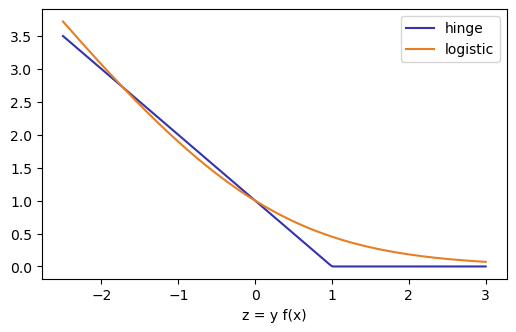

In [9]:
def hinge(z):
    return np.maximum(0, 1 - np.asarray(z, float))

def logistic(z):
    return np.log2(1 + np.exp(-np.asarray(z, float)))

zs = np.linspace(-2.5, 3, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(zs, hinge(zs), color=BLUE, label="hinge")
plt.plot(zs, logistic(zs), color=ORANGE, label="logistic")
plt.xlabel("z = y f(x)"); plt.legend(); plt.show()

In [10]:
# Checkpoint: the hinge is exactly 0 for z >= 1, the logistic loss never is
for zz in [-1, 0, 0.5, 1, 2, 3, 5]:
    print(f"z={zz:>4}: hinge={hinge(zz):.3f}  logistic={logistic(zz):.3f}")
# expected hinge: 2, 1, 0.5, 0, 0, 0, 0   logistic: 1.895, 1, 0.684, 0.452, 0.183, 0.070, 0.010

z=  -1: hinge=2.000  logistic=1.895
z=   0: hinge=1.000  logistic=1.000
z= 0.5: hinge=0.500  logistic=0.684
z=   1: hinge=0.000  logistic=0.452
z=   2: hinge=0.000  logistic=0.183
z=   3: hinge=0.000  logistic=0.070
z=   5: hinge=0.000  logistic=0.010


**Task 3.2 (slacks).** The slack of a point is the smallest $\xi\ge0$ with $y f \ge 1-\xi$, i.e. $\xi = \max(0, 1 - yf)$ — the hinge. Compute the slacks of three class-$(+1)$ points with $yf = 1.5,\ 0.6,\ -0.3$. Check that $\sum\xi$ is at least the number of misclassified points.

In [11]:
yf = np.array([1.5, 0.6, -0.3])
xi = np.maximum(0, 1 - yf)
print("slacks:", xi, "  sum:", xi.sum(), "  errors:", np.sum(yf < 0))

slacks: [0.  0.4 1.3]   sum: 1.7000000000000002   errors: 1


In [12]:
# Checkpoint: slacks [0, 0.4, 1.3], sum 1.7 >= 1 error

## Part 4 — The soft margin on the 1-D example

Seven clients on a line; $x=1.5$ is an outlier labelled $-1$:

| $x$ | −3 | −2 | −1 | 1 | 2 | 3 | 1.5 |
|---|---|---|---|---|---|---|---|
| $y$ | −1 | −1 | −1 | +1 | +1 | +1 | −1 |

Soft-margin cost:
$$J(w,b) = \tfrac12 w^2 + C\sum_i \max\big(0,\ 1 - y_i(wx_i+b)\big).$$

**Task 4.1.** Write `J(w, b, C)`. Evaluate the two solutions of the lecture: $(0.4,-0.2)$ for $C=0.1$ and $(2/3,-1/3)$ for $C=10$.

In [13]:
x1 = np.array([-3, -2, -1, 1, 2, 3, 1.5])
y1 = np.array([-1, -1, -1, 1, 1, 1, -1])

def J(w, b, C, x=x1, y=y1):
    return 0.5 * w**2 + C * hinge(y * (w * x + b)).sum()

for (w_, b_, C) in [(0.4, -0.2, 0.1), (2/3, -1/3, 10)]:
    h = hinge(y1 * (w_ * x1 + b_))
    print(f"C={C:>4}: w={w_:.3f} b={b_:.3f}  hinges={h}  sum={h.sum():.3f}  J={J(w_, b_, C):.3f}  width={2/w_:.1f}")

C= 0.1: w=0.400 b=-0.200  hinges=[0.  0.  0.4 0.8 0.4 0.  1.4]  sum=3.000  J=0.380  width=5.0
C=  10: w=0.667 b=-0.333  hinges=[0.    0.    0.    0.667 0.    0.    1.667]  sum=2.333  J=23.556  width=3.0


In [14]:
# Checkpoint: C=0.1 -> hinges [0 0 0.4 0.8 0.4 0 1.4], sum 3.0, J 0.38, width 5
#             C=10  -> sum 2.333, J 23.556, width 3

**Task 4.2 (no solver!).** Find the minimum of $J$ by brute force: evaluate $J$ on a grid of $(w,b)$ values and keep the smallest. Do it for $C=0.1$ and $C=10$, and compare with `SVC(kernel="linear", C=C)`.

In [15]:
W_grid = np.linspace(0, 1.5, 301)
B_grid = np.linspace(-1.5, 1.5, 301)
Wg, Bg = np.meshgrid(W_grid, B_grid, indexing="ij")
for C in [0.1, 10]:
    Jg = 0.5 * Wg**2 + C * hinge(y1 * (Wg[..., None] * x1 + Bg[..., None])).sum(-1)
    i, j = np.unravel_index(Jg.argmin(), Jg.shape)
    s = SVC(kernel="linear", C=C).fit(x1[:, None], y1)
    print(f"C={C}: grid w={W_grid[i]:.3f} b={B_grid[j]:.3f} J={Jg[i, j]:.3f} | SVC w={s.coef_[0, 0]:.3f} b={s.intercept_[0]:.3f}")

C=0.1: grid w=0.400 b=-0.200 J=0.380 | SVC w=0.400 b=-0.200
C=10: grid w=0.670 b=-0.340 J=23.574 | SVC w=0.667 b=-0.333


**Task 4.3.** Plot the street of both solutions on the line, then plot the street width $2/w$ and the total hinge as functions of $C$ (log scale, $C$ from $0.01$ to $100$). Comment: does a large $C$ give zero violations here? What happens for $C=0.01$?

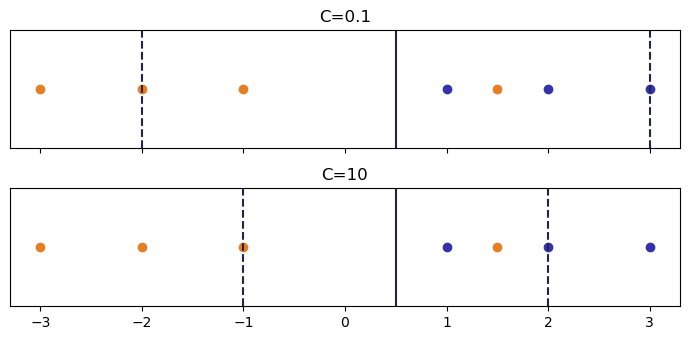

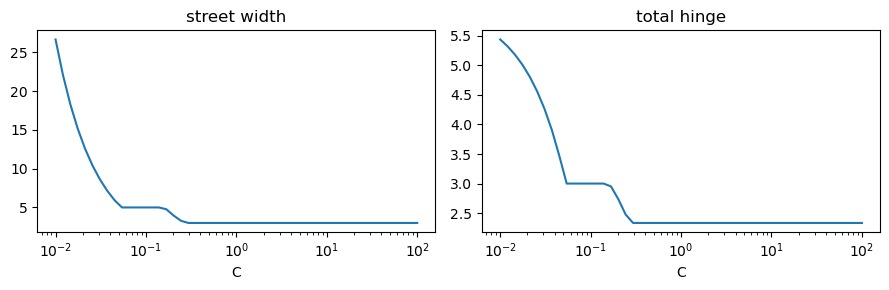

In [16]:
X1d = x1[:, None].astype(float); y1d = y1.astype(float)
fig, axs = plt.subplots(2, 1, figsize=(7, 3.5), sharex=True)
for ax, (w_, b_), C in zip(axs, [(0.4, -0.2), (2/3, -1/3)], [0.1, 10]):
    ax.scatter(x1[y1 > 0], np.zeros((y1 > 0).sum()), color=BLUE)
    ax.scatter(x1[y1 < 0], np.zeros((y1 < 0).sum()), color=ORANGE)
    ax.axvline(-b_ / w_, color=NAVY)
    ax.axvline((1 - b_) / w_, color=NAVY, ls="--"); ax.axvline((-1 - b_) / w_, color=NAVY, ls="--")
    ax.set_title(f"C={C}"); ax.set_yticks([])
plt.tight_layout(); plt.show()

Cs = np.logspace(-2, 2, 50)
widths, hs = [], []
for C in Cs:
    s = SVC(kernel="linear", C=C).fit(X1d, y1d)
    widths.append(2 / abs(s.coef_[0, 0]))
    hs.append(hinge(y1d * s.decision_function(X1d)).sum())
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
axs[0].semilogx(Cs, widths); axs[0].set_title("street width")
axs[1].semilogx(Cs, hs); axs[1].set_title("total hinge")
for a in axs: a.set_xlabel("C")
plt.tight_layout(); plt.show()

**Answer 4.3.** No. The point x = 1.5 (label -1) is among the positive points, so the data are not separable. The total hinge stays above 2.33 for any C. For C = 0.01, w is very small, the street is very wide and many points are inside it.

## Part 5 — Train the SVM yourself: sub-gradient descent

The cost $J(w,b)=\tfrac12\lVert w\rVert^2 + C\sum_i \max(0, 1-y_i f(x_i))$ has a kink, but away from it:
$$g_w = w - C\!\!\sum_{i:\,y_if_i<1}\!\! y_i x_i,\qquad g_b = -C\!\!\sum_{i:\,y_if_i<1}\!\! y_i .$$
Only the **violators** ($y_if_i<1$) push. Update: $w \leftarrow w-\eta_t g_w$, $b\leftarrow b-\eta_t g_b$ with a shrinking step $\eta_t = \eta_0/\sqrt{t}$.

**Task 5.1.** Write `svm_subgradient(X, y, C, eta0, n_iter)` returning $w$, $b$ and the history of $J$.

In [17]:
def objective(w, b, X, y, C):
    return 0.5 * w @ w + C * hinge(y * (X @ w + b)).sum()

def svm_subgradient(X, y, C=1.0, eta0=0.5, n_iter=5000):
    w, b = np.zeros(X.shape[1]), 0.0
    history = []
    for t in range(1, n_iter + 1):
        viol = y * (X @ w + b) < 1
        g_w = w - C * y[viol] @ X[viol]
        g_b = -C * y[viol].sum()
        eta = eta0 / np.sqrt(t)
        w, b = w - eta * g_w, b - eta * g_b
        history.append(objective(w, b, X, y, C))
    return w, b, history

**Task 5.2.** Check the first step by hand on the 4 points (lecture): from $w=(0,0)$, $b=0$, $\eta_1=0.5$, $C=1$ you should get $w=(2,1)$, $b=0$. Then run 20 000 iterations: you should approach $w=(1,1)$, $b=-3$.

after 1 step : [2. 1.] 0.0    expected [2, 1], 0
after 20000  : [0.991 0.991] -2.968    expected close to [1, 1], -3


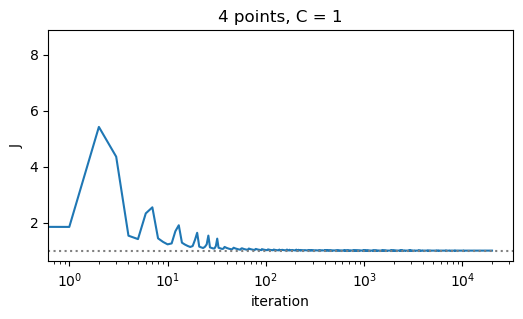

In [18]:
w_1, b_1, _ = svm_subgradient(X4, y4, C=1.0, eta0=0.5, n_iter=1)
print("after 1 step :", w_1, b_1, "   expected [2, 1], 0")
w_, b_, hist = svm_subgradient(X4, y4, C=1.0, eta0=0.5, n_iter=20000)
print("after 20000  :", w_.round(3), round(b_, 3), "   expected close to [1, 1], -3")
plt.figure(figsize=(6, 3)); plt.semilogx(hist); plt.axhline(1, ls=":", color="gray")
plt.xlabel("iteration"); plt.ylabel("J"); plt.title("4 points, C = 1"); plt.show()

**Task 5.3.** Same on the 1-D example with $C=0.1$, $\eta_0=1$: the first step should give $w=1.05$, $b=-0.1$, and the limit $w=0.4$, $b=-0.2$, $J=0.38$.

In [19]:
w_a, b_a, _ = svm_subgradient(X1d, y1d, C=0.1, eta0=1.0, n_iter=1)
print("one step:", w_a, b_a, "  expected 1.05, -0.1")
w_a, b_a, h_a = svm_subgradient(X1d, y1d, C=0.1, eta0=1.0, n_iter=20000)
print("limit:", w_a, round(b_a, 3), "J =", round(h_a[-1], 3))

one step: [1.05] -0.1   expected 1.05, -0.1
limit: [0.399] -0.201 J = 0.38


## Part 6 — Support vectors and the three kinds of points

scikit-learn solves the dual. For each support vector it stores $\alpha_i y_i$ in `dual_coef_`. Every multiplier satisfies $0\le\alpha_i\le C$:

| $\alpha_i$ | position |
|---|---|
| $0$ | outside the street — ignored |
| $0<\alpha_i<C$ | exactly on a kerb ($y_if=1$) |
| $C$ | inside the street or on the wrong side |

**Task 6.1.** Fit `SVC(kernel="linear", C=10)` on the 1-D data. Recover all $\alpha_i$, classify each point, and check $\sum_i\alpha_iy_i=0$ and $w=\sum_i\alpha_iy_ix_i$.

In [20]:
C = 10
m = SVC(kernel="linear", C=C).fit(X1d, y1d)
alpha = np.zeros(len(x1))
alpha[m.support_] = np.abs(m.dual_coef_[0])
yf6 = y1d * m.decision_function(X1d)
for xi_, yf_, a_ in zip(x1, yf6, alpha):
    kind = "outside" if a_ < 1e-8 else ("on kerb" if a_ < C - 1e-8 else "inside / wrong")
    print(f"x={xi_:>4}: y*f={yf_:.3f} alpha={a_:.3f} {kind}")
print("sum(alpha*y) =", round((alpha * y1d).sum(), 6))
print("w =", (alpha * y1d) @ x1, " sklearn w =", m.coef_[0, 0])

x=-3.0: y*f=2.333 alpha=0.000 outside
x=-2.0: y*f=1.667 alpha=0.000 outside
x=-1.0: y*f=1.000 alpha=1.889 on kerb
x= 1.0: y*f=0.333 alpha=10.000 inside / wrong
x= 2.0: y*f=1.000 alpha=1.889 on kerb
x= 3.0: y*f=1.667 alpha=0.000 outside
x= 1.5: y*f=-0.667 alpha=10.000 inside / wrong
sum(alpha*y) = 0.0
w = 0.6666666666666661  sklearn w = 0.6666666666666679


In [21]:
# Checkpoint: x=-1 and x=2 on the kerbs with alpha = 17/9 = 1.889;
#             x=1 and x=1.5 capped at alpha = 10; the other three alpha = 0; w = 0.6667

## Part 7 — Kernels

**Task 7.1 — the kernel trick.** With $\phi(x)=(x_1^2,\ \sqrt2\,x_1x_2,\ x_2^2)$ check that $\phi(x)^\top\phi(z)=(x^\top z)^2$ for $x=(1,2)$, $z=(3,1)$ and for 1000 random pairs.

In [22]:
def phi(x):
    return np.array([x[0]**2, np.sqrt(2) * x[0] * x[1], x[1]**2])

x, zv = np.array([1., 2.]), np.array([3., 1.])
print(phi(x) @ phi(zv), (x @ zv)**2)
rng = np.random.default_rng(0)
P = rng.normal(size=(1000, 2, 2))
print("max error:", max(abs(phi(a) @ phi(c) - (a @ c)**2) for a, c in P))

25.0 25.0
max error: 2.1316282072803006e-14


**Task 7.2 — circles.** On `make_circles`, compare (a) a linear SVM on $(x_1,x_2)$, (b) a linear SVM on the single new feature $z=x_1^2+x_2^2$, (c) an RBF SVM. Use 5-fold cross-validation.

linear on (x1,x2) 0.485
linear on z 1.0
RBF 1.0


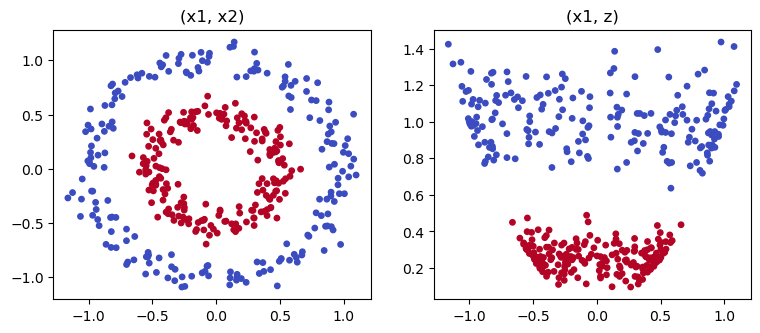

In [23]:
Xc, yc = make_circles(400, noise=0.08, factor=0.5, random_state=0)
zc = (Xc**2).sum(axis=1, keepdims=True)
for name, X_, mod in [("linear on (x1,x2)", Xc, SVC(kernel="linear")), ("linear on z", zc, SVC(kernel="linear")), ("RBF", Xc, SVC(kernel="rbf"))]:
    print(name, cross_val_score(mod, X_, yc, cv=5).mean().round(3))
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
axs[0].scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap="coolwarm", s=15)
axs[1].scatter(Xc[:, 0], zc[:, 0], c=yc, cmap="coolwarm", s=15)
axs[0].set_title("(x1, x2)"); axs[1].set_title("(x1, z)")
plt.show()

**Task 7.3 — an RBF prediction by hand.** For an RBF SVM,
$$f(x)=\sum_{i\in SV}\alpha_iy_i\,K(x_i,x)+b,\qquad K(x,z)=\exp(-\gamma\lVert x-z\rVert^2).$$
Fit `SVC(kernel="rbf", gamma=1, C=1)` on 200 moons. Recompute `decision_function` for 5 new points **yourself** using `support_vectors_`, `dual_coef_` (which holds $\alpha_iy_i$) and `intercept_`.

In [24]:
Xm, ym = make_moons(200, noise=0.25, random_state=0)
rbf = SVC(kernel="rbf", gamma=1.0, C=1.0).fit(Xm, ym)
Xnew = np.array([[0., 0.5], [1., 0.], [-1., 0.5], [2., 0.], [0.5, -0.3]])

def f_by_hand(xnew, model, gamma):
    d2 = ((model.support_vectors_ - xnew)**2).sum(axis=1)
    return model.dual_coef_[0] @ np.exp(-gamma * d2) + model.intercept_[0]

print(np.array([f_by_hand(p, rbf, 1.0) for p in Xnew]))
print(rbf.decision_function(Xnew))

[-0.083  0.017 -1.66   1.54   1.485]
[-0.083  0.017 -1.66   1.54   1.485]


**Task 7.4 — the knobs $\gamma$ and $C$.** Draw the decision regions for $\gamma\in\{0.1, 1, 50\}$ ($C=1$). Then grid-search $C,\gamma\in\{0.1,1,10,100\}$ with 5-fold CV.

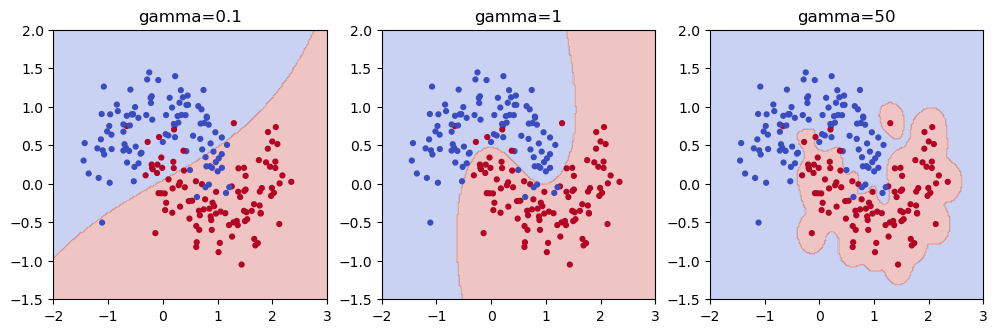

{'C': 0.1, 'gamma': 10} 0.94


In [25]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
gx, gy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
for ax, g in zip(axs, [0.1, 1, 50]):
    s = SVC(kernel="rbf", gamma=g, C=1).fit(Xm, ym)
    ax.contourf(gx, gy, s.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape), alpha=0.3, cmap="coolwarm")
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", s=12); ax.set_title(f"gamma={g}")
plt.show()
gs = GridSearchCV(SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": [0.1, 1, 10, 100]}, cv=5).fit(Xm, ym)
print(gs.best_params_, round(gs.best_score_, 3))

## Part 8 — A real data set: breast cancer

569 patients, 30 features, labels $\pm1$.

**Task 8.1.** Train your sub-gradient SVM (`C=1`, a small step, many iterations) on the **standardised** training set and compare objective and test accuracy with `SVC(kernel="linear", C=1)`.

**Task 8.2.** Show why scaling matters: compare an RBF SVM with and without `StandardScaler` (5-fold CV on the training set).

In [26]:
Xb, yb = load_breast_cancer(return_X_y=True); yb = 2 * yb - 1
Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=0.3, random_state=0, stratify=yb)
sc = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
w_b, b_b, h_b = svm_subgradient(Xtr_s, ytr.astype(float), C=1.0, eta0=0.01, n_iter=20000)
lin = SVC(kernel="linear", C=1).fit(Xtr_s, ytr)
print("mine : J =", round(h_b[-1], 3), " test acc =", round(np.mean(np.sign(Xte_s @ w_b + b_b) == yte), 3))
print("SVC  : J =", round(objective(lin.coef_[0], lin.intercept_[0], Xtr_s, ytr, 1.0), 3), " test acc =", round(lin.score(Xte_s, yte), 3))
print("RBF no scaler :", cross_val_score(SVC(kernel="rbf"), Xtr, ytr, cv=5).mean().round(3))
print("RBF scaler    :", cross_val_score(make_pipeline(StandardScaler(), SVC(kernel="rbf")), Xtr, ytr, cv=5).mean().round(3))

mine : J = 14.222  test acc = 0.953
SVC  : J = 14.2  test acc = 0.953
RBF no scaler : 0.922
RBF scaler    : 0.98


## Wrap-up questions

1. A point has $y f(x) = 0.7$. Is it misclassified? What is its hinge loss?
2. In Part 4, why does the total hinge never reach 0, however large $C$ is?
3. In Part 5, why do we use a step $\eta_t$ that shrinks with $t$?
4. In Part 6, which points could you delete without changing the SVM at all?
5. In Part 7.3, how many numbers does the RBF model need to store to predict? Compare with the linear SVM.
6. In Part 8, why must the scaler be fitted on the training set only?

**Answers.**
1. No, it is on the right side. Hinge loss = 0.3.
2. The outlier x = 1.5 is always on the wrong side or in the street, so it always costs.
3. Big steps at the start go fast. Small steps at the end give a stable result.
4. The points with alpha = 0 (outside the street).
5. RBF: all support vectors and their alpha values (about n_SV x (d + 1) numbers). Linear: only d + 1 numbers (w and b).
6. The test set must stay unseen. Fitting on it would leak information.